In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor,
                          export_text, plot_tree)


def doc_csv(ten_tep):
    """Doc tep csv trong thu muc data/, neu khong co thi doc o thu muc hien tai."""
    duong_dan = os.path.join("data", ten_tep)
    if not os.path.exists(duong_dan):
        duong_dan = ten_tep
    return pd.read_csv(duong_dan)


# Du lieu khach vay, chia 75/25 giong het tai lieu
df = doc_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print("Kich thuoc bang:", df.shape)
print("So khach de hoc:", len(X_tr), "| so khach de kiem tra:", len(X_te))

Kich thuoc bang: (600, 5)
So khach de hoc: 450 | so khach de kiem tra: 150


## 2.2. Mười khách để tính tay: tự tính chỉ số Gini

In [2]:
# Muoi khach vay de tinh tay, giong het bang tren slide
nho = pd.DataFrame({
    "thu_nhap": [6, 8, 9, 11, 13, 15, 18, 20, 25, 30],
    "co_viec_on_dinh": [0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
    "tra_dung_han": [0, 1, 0, 0, 1, 1, 0, 1, 1, 1],
})
y_nho = nho["tra_dung_han"].to_numpy()


def gini(nhan):
    """Chi so Gini cua mot nut co hai lop."""
    if len(nhan) == 0:
        return 0.0
    p1 = nhan.mean()
    return 1 - p1 ** 2 - (1 - p1) ** 2


def gini_sau_chia(di_trai):
    """Gini trung binh co trong so cua hai nhanh."""
    trai, phai = y_nho[di_trai], y_nho[~di_trai]
    n = len(y_nho)
    return len(trai) / n * gini(trai) + len(phai) / n * gini(phai)


g_goc = gini(y_nho)
print(f"Gini cua nut goc: {g_goc:.4f}")
print()

# Thu moi nguong nam giua hai muc thu nhap lien nhau
thu = nho["thu_nhap"].to_numpy()
muc = np.sort(np.unique(thu))
print("Cau hoi 'thu_nhap <= nguong ?'")
print(" nguong    Gini sau chia   Gini giam")
for a, b in zip(muc[:-1], muc[1:]):
    nguong = (a + b) / 2
    g = gini_sau_chia(thu <= nguong)
    print(f" {nguong:6.1f}    {g:13.4f}   {g_goc - g:9.4f}")
print()

# Cau hoi thu hai: co viec lam on dinh khong
viec = nho["co_viec_on_dinh"].to_numpy()
g_viec = gini_sau_chia(viec == 0)
print("Cau hoi 'co viec on dinh ?'")
print(f" Gini sau chia {g_viec:.4f}, Gini giam {g_goc - g_viec:.4f}")
print()

# De scikit-learn tu chon cau hoi dau tien roi so voi bang o tren
cot_nho = ["thu_nhap", "co_viec_on_dinh"]
cay_mot_tang = DecisionTreeClassifier(max_depth=1, random_state=0)
cay_mot_tang.fit(nho[cot_nho], y_nho)
print("Cay mot tang do scikit-learn chon:")
print(export_text(cay_mot_tang, feature_names=cot_nho, show_weights=True))

Gini cua nut goc: 0.4800

Cau hoi 'thu_nhap <= nguong ?'
 nguong    Gini sau chia   Gini giam
    7.0           0.4000      0.0800
    8.5           0.4750      0.0050
   10.0           0.4190      0.0610
   12.0           0.3167      0.1633
   14.0           0.4000      0.0800
   16.5           0.4500      0.0300
   19.0           0.3429      0.1371
   22.5           0.4000      0.0800
   27.5           0.4444      0.0356

Cau hoi 'co viec on dinh ?'
 Gini sau chia 0.4190, Gini giam 0.0610

Cay mot tang do scikit-learn chon:
|--- thu_nhap <= 12.00
|   |--- weights: [3.00, 1.00] class: 0
|--- thu_nhap >  12.00
|   |--- weights: [1.00, 5.00] class: 1



**Nhận xét:** Nút gốc có 6 khách đúng hạn và 4 khách trễ hạn nên Gini = 1 − 0.6² − 0.4² = 0.4800. Trong chín ngưỡng thu nhập đã thử, ngưỡng 12.0 làm Gini giảm nhiều nhất (0.1633), ngưỡng 19.0 đứng thứ hai (0.1371). Câu hỏi về việc làm chỉ giảm 0.0610, kém xa. Scikit-learn chọn đúng câu hỏi `thu_nhap <= 12.00`, khớp với phép tính tay. Mọi ngưỡng giữa 11 và 13 chia mười khách giống hệt nhau nên chỉ cần thử trung điểm. Dòng `weights: [3.00, 1.00]` là số khách lớp 0 đứng trước, lớp 1 đứng sau. Cây chọn câu hỏi tốt nhất ngay lúc đó rồi lặp lại ở từng nhánh, không nhìn trước các bước sau, nên gọi là chọn tham lam.

## 3. Cây đầu tiên trên dữ liệu khách vay (năm lá)

In [3]:
print(df.head())
print()
print("Ty le khach tra dung han:", round(df["tra_dung_han"].mean(), 2))
print()

# Gioi han cay chi duoc co 5 la de con doc duoc bang mat
cay_nam_la = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay_nam_la.fit(X_tr, y_tr)

print(f"Do sau {cay_nam_la.get_depth()}, so la {cay_nam_la.get_n_leaves()}")
print(export_text(cay_nam_la, feature_names=list(X.columns),
                  show_weights=True, decimals=3))

a_hoc = accuracy_score(y_tr, cay_nam_la.predict(X_tr))
a_kt = accuracy_score(y_te, cay_nam_la.predict(X_te))
print(f"Accuracy tap hoc      : {a_hoc:.4f}")
print(f"Accuracy tap kiem tra : {a_kt:.4f}")
print()

# Hai khach moi, di theo cay de biet moi nguoi roi vao la nao
khach_moi = pd.DataFrame({
    "thu_nhap": [20.0, 10.0],
    "ty_le_no": [0.4, 0.3],
    "co_viec_on_dinh": [1, 0],
    "so_nguoi_phu_thuoc": [2, 1],
})
du_doan = cay_nam_la.predict(khach_moi)
xac_suat = cay_nam_la.predict_proba(khach_moi)[:, 1]
for i in range(len(khach_moi)):
    ket = "dung han" if du_doan[i] == 1 else "tre han"
    print(f"Khach {i + 1}: {ket}, xac suat dung han {xac_suat[i]:.2f}")

   thu_nhap  ty_le_no  co_viec_on_dinh  so_nguoi_phu_thuoc  tra_dung_han
0       9.4      0.18                0                   4             0
1      15.8      0.70                0                   2             1
2       6.1      0.79                0                   0             0
3      19.4      1.13                1                   4             0
4      24.8      0.33                1                   0             1

Ty le khach tra dung han: 0.49

Do sau 3, so la 5
|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- co_viec_on_dinh <= 0.500
|   |   |   |--- weights: [33.000, 6.000] class: 0
|   |   |--- co_viec_on_dinh >  0.500
|   |   |   |--- weights: [35.000, 47.000] class: 1
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Accuracy tap hoc      : 0.7978

## 4. Cây học vẹt và cách chọn độ sâu

In [4]:
# Khong dat gioi han nao, cay chia toi khi moi la deu thuan
cay_tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
print("Cay moc tu do")
print(f" do sau {cay_tu_do.get_depth()}, so la {cay_tu_do.get_n_leaves()}")
a_hoc = accuracy_score(y_tr, cay_tu_do.predict(X_tr))
a_kt = accuracy_score(y_te, cay_tu_do.predict(X_te))
print(f" tap hoc {a_hoc:.4f}, tap kiem tra {a_kt:.4f}")
print()

# Chon do sau chi dua tren tap hoc
print("Do sau   tap hoc   kiem dinh cheo")
diem_theo_do_sau = {}
for do_sau in range(1, 16):
    mo_hinh = DecisionTreeClassifier(max_depth=do_sau, random_state=0)
    diem_theo_do_sau[do_sau] = cross_val_score(mo_hinh, X_tr, y_tr, cv=5).mean()
    hoc = accuracy_score(y_tr, mo_hinh.fit(X_tr, y_tr).predict(X_tr))
    print(f" {do_sau:2d}      {hoc:.4f}    {diem_theo_do_sau[do_sau]:.4f}")
do_sau_tot = max(diem_theo_do_sau, key=diem_theo_do_sau.get)
print()

# Chon xong moi mo tap kiem tra, va chi mo mot lan
cay_tot = DecisionTreeClassifier(max_depth=do_sau_tot, random_state=0)
cay_tot.fit(X_tr, y_tr)
print(f"Do sau tot nhat = {do_sau_tot}, cay co {cay_tot.get_n_leaves()} la")
acc_cay_tot = accuracy_score(y_te, cay_tot.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc_cay_tot:.4f}")

Cay moc tu do
 do sau 13, so la 92
 tap hoc 1.0000, tap kiem tra 0.7667

Do sau   tap hoc   kiem dinh cheo
  1      0.7467    0.7244
  2      0.7711    0.7378
  3      0.8000    0.7511
  4      0.8644    0.8089
  5      0.8978    0.8333
  6      0.9133    0.8156
  7      0.9400    0.8067
  8      0.9600    0.7733


  9      0.9800    0.7800


 10      0.9911    0.7822
 11      0.9933    0.7756
 12      0.9978    0.7778
 13      1.0000    0.7733
 14      1.0000    0.7733
 15      1.0000    0.7733

Do sau tot nhat = 5, cay co 27 la
Accuracy tren tap kiem tra = 0.8533


## 5. Cây không cần chuẩn hoá

In [5]:
def cay_sau_5():
    return DecisionTreeClassifier(max_depth=5, random_state=0)


# Cay 1: du lieu goc
cay_goc = cay_sau_5().fit(X_tr, y_tr)
du_goc = cay_goc.predict(X_te)

# Cay 2: du lieu da chuan hoa, trung binh tinh tren rieng tap hoc
bo_chuan_hoa = StandardScaler().fit(X_tr)
cay_chuan = cay_sau_5().fit(bo_chuan_hoa.transform(X_tr), y_tr)
du_chuan = cay_chuan.predict(bo_chuan_hoa.transform(X_te))

# Cay 3: doi thu nhap tu trieu dong sang nghin dong
X_tr_nghin, X_te_nghin = X_tr.copy(), X_te.copy()
X_tr_nghin["thu_nhap"] = X_tr_nghin["thu_nhap"] * 1000
X_te_nghin["thu_nhap"] = X_te_nghin["thu_nhap"] * 1000
cay_nghin = cay_sau_5().fit(X_tr_nghin, y_tr)
du_nghin = cay_nghin.predict(X_te_nghin)

print("Accuracy tren tap kiem tra")
print(f" du lieu goc         : {accuracy_score(y_te, du_goc):.4f}")
print(f" da chuan hoa        : {accuracy_score(y_te, du_chuan):.4f}")
print(f" thu nhap nghin dong : {accuracy_score(y_te, du_nghin):.4f}")
print()
print("So khach bi doan khac cay goc")
print(f" da chuan hoa        : {(du_chuan != du_goc).sum()}")
print(f" thu nhap nghin dong : {(du_nghin != du_goc).sum()}")
print()
print("Nguong cua cau hoi goc")
print(f" du lieu goc         : {cay_goc.tree_.threshold[0]:.2f}")
print(f" thu nhap nghin dong : {cay_nghin.tree_.threshold[0]:.2f}")

Accuracy tren tap kiem tra
 du lieu goc         : 0.8533
 da chuan hoa        : 0.8533
 thu nhap nghin dong : 0.8533

So khach bi doan khac cay goc
 da chuan hoa        : 0
 thu nhap nghin dong : 0

Nguong cua cau hoi goc
 du lieu goc         : 15.05
 thu nhap nghin dong : 15050.00


## 6. Rừng ngẫu nhiên

In [6]:
# Boc mau co hoan lai: rut 450 lan tu 450 khach
rng = np.random.default_rng(0)
n = len(X_tr)
chi_so = rng.integers(0, n, n)
so_khach_khac = len(np.unique(chi_so))
print(f"Boc {n} lan, co {so_khach_khac} khach khac nhau ({so_khach_khac / n:.0%})")
print()

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
print("Rung 200 cay")
print(f" tap hoc       : {accuracy_score(y_tr, rung.predict(X_tr)):.4f}")
print(f" tap kiem tra  : {accuracy_score(y_te, rung.predict(X_te)):.4f}")
print()

print("So cay   accuracy tap kiem tra")
for so_cay in [1, 10, 50, 200, 400]:
    r = RandomForestClassifier(n_estimators=so_cay, random_state=0)
    r.fit(X_tr, y_tr)
    print(f" {so_cay:4d}    {accuracy_score(y_te, r.predict(X_te)):.4f}")
print()

# Bang tong ket ba mo hinh tren cung tap kiem tra
ba_mo_hinh = {
    "Cay moc tu do": DecisionTreeClassifier(random_state=0),
    "Cay sau 5": DecisionTreeClassifier(max_depth=5, random_state=0),
    "Rung 200 cay": rung,
}
print("Mo hinh          tap hoc   tap kiem tra")
for ten, mo_hinh in ba_mo_hinh.items():
    mo_hinh.fit(X_tr, y_tr)
    a = accuracy_score(y_tr, mo_hinh.predict(X_tr))
    b = accuracy_score(y_te, mo_hinh.predict(X_te))
    print(f" {ten:14s} {a:.4f}     {b:.4f}")

Boc 450 lan, co 286 khach khac nhau (64%)



Rung 200 cay
 tap hoc       : 1.0000
 tap kiem tra  : 0.9000

So cay   accuracy tap kiem tra
    1    0.7933


   10    0.8467


   50    0.8733


  200    0.9000


  400    0.9000

Mo hinh          tap hoc   tap kiem tra
 Cay moc tu do  1.0000     0.7667
 Cay sau 5      0.8978     0.8533
 Rung 200 cay   1.0000     0.9000


## 7. Độ quan trọng của đặc trưng

Do quan trong, bon cot that
thu_nhap              0.479
ty_le_no              0.339
so_nguoi_phu_thuoc    0.093
co_viec_on_dinh       0.088
Tong: 1.0

Do quan trong, them mot cot ngau nhien
thu_nhap              0.427
ty_le_no              0.270
so_ngau_nhien         0.150
co_viec_on_dinh       0.077
so_nguoi_phu_thuoc    0.076


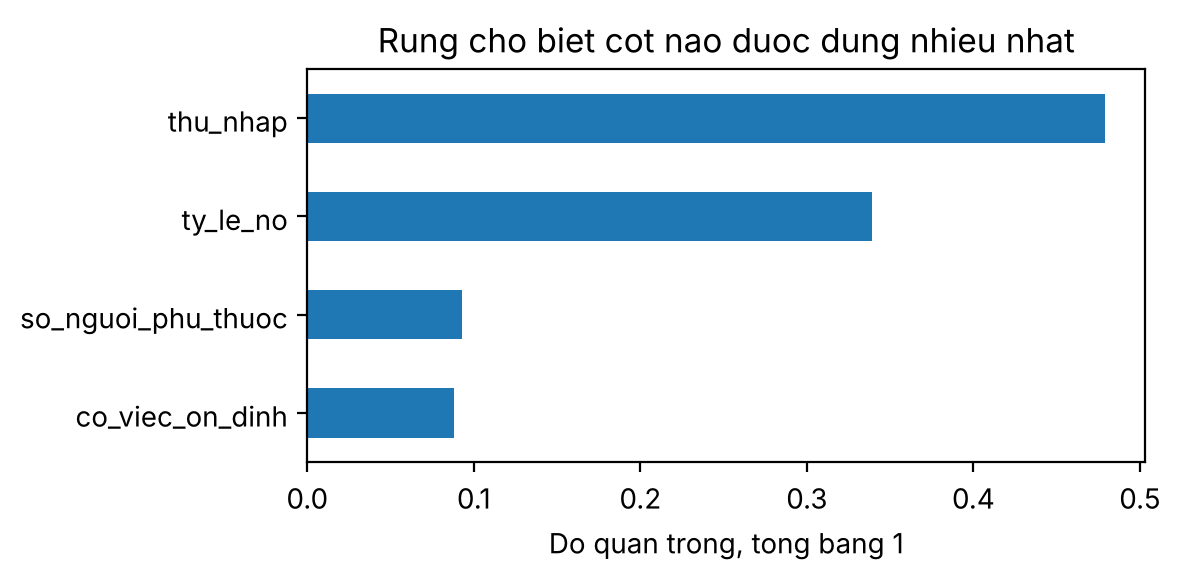

In [7]:
rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
do_quan_trong = pd.Series(rung.feature_importances_, index=X.columns)
print("Do quan trong, bon cot that")
print(do_quan_trong.sort_values(ascending=False).round(3).to_string())
print("Tong:", round(do_quan_trong.sum(), 3))
print()

# Them mot cot toan so ngau nhien, chang lien quan gi toi viec tra no
rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))
rung_nn = RandomForestClassifier(n_estimators=200, random_state=0)
rung_nn.fit(X_tr_nn, y_tr)
do_quan_trong_nn = pd.Series(rung_nn.feature_importances_, index=X_tr_nn.columns)
print("Do quan trong, them mot cot ngau nhien")
print(do_quan_trong_nn.sort_values(ascending=False).round(3).to_string())

# Ve bieu do cot cho bon cot that
do_quan_trong.sort_values().plot.barh(color="tab:blue", figsize=(6, 3))
plt.xlabel("Do quan trong, tong bang 1")
plt.title("Rung cho biet cot nao duoc dung nhieu nhat")
plt.tight_layout()
plt.show()

## 8. Cây cho bài toán hồi quy

In [8]:
gia_nha = doc_csv("gia_nha.csv")
X_gia = gia_nha[["dien_tich"]]
y_gia = gia_nha["gia"]

# Cung cach chia voi bai 1 de so sanh cong bang
X_gia_tr, X_gia_te, y_gia_tr, y_gia_te = train_test_split(
    X_gia, y_gia, test_size=0.2, random_state=42
)

cay_hoi_quy = DecisionTreeRegressor(max_depth=3, random_state=0)
cay_hoi_quy.fit(X_gia_tr, y_gia_tr)
duong_thang = LinearRegression().fit(X_gia_tr, y_gia_tr)

print(f"Cay hoi quy sau 3 co {cay_hoi_quy.get_n_leaves()} la")
print(export_text(cay_hoi_quy, feature_names=["dien_tich"], decimals=1))

print("MAE tren tap kiem tra (ty dong)")
mae_cay = mean_absolute_error(y_gia_te, cay_hoi_quy.predict(X_gia_te))
mae_duong = mean_absolute_error(y_gia_te, duong_thang.predict(X_gia_te))
print(f" Cay sau 3   : {mae_cay:.4f}")
print(f" Duong thang : {mae_duong:.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print(" dien tich      cay   duong thang")
for dien_tich, gia_cay, gia_duong in zip(can_moi["dien_tich"],
                                         cay_hoi_quy.predict(can_moi),
                                         duong_thang.predict(can_moi)):
    print(f" {dien_tich:6.0f} m2    {gia_cay:6.2f}   {gia_duong:6.2f}")

Cay hoi quy sau 3 co 8 la
|--- dien_tich <= 73.9
|   |--- dien_tich <= 64.7
|   |   |--- dien_tich <= 50.5
|   |   |   |--- value: [4.2]
|   |   |--- dien_tich >  50.5
|   |   |   |--- value: [4.9]
|   |--- dien_tich >  64.7
|   |   |--- dien_tich <= 68.5
|   |   |   |--- value: [5.3]
|   |   |--- dien_tich >  68.5
|   |   |   |--- value: [5.9]
|--- dien_tich >  73.9
|   |--- dien_tich <= 93.8
|   |   |--- dien_tich <= 82.5
|   |   |   |--- value: [6.8]
|   |   |--- dien_tich >  82.5
|   |   |   |--- value: [7.4]
|   |--- dien_tich >  93.8
|   |   |--- dien_tich <= 107.7
|   |   |   |--- value: [8.3]
|   |   |--- dien_tich >  107.7
|   |   |   |--- value: [9.4]

MAE tren tap kiem tra (ty dong)
 Cay sau 3   : 0.5039
 Duong thang : 0.2578

Du doan cho bon can moi (ty dong)
 dien tich      cay   duong thang
     60 m2      4.92     5.12
    100 m2      8.32     8.24
    150 m2      9.40    12.13
    250 m2      9.40    19.91


## 9. Bài tập

### Bài tập 1: Tự vẽ cây

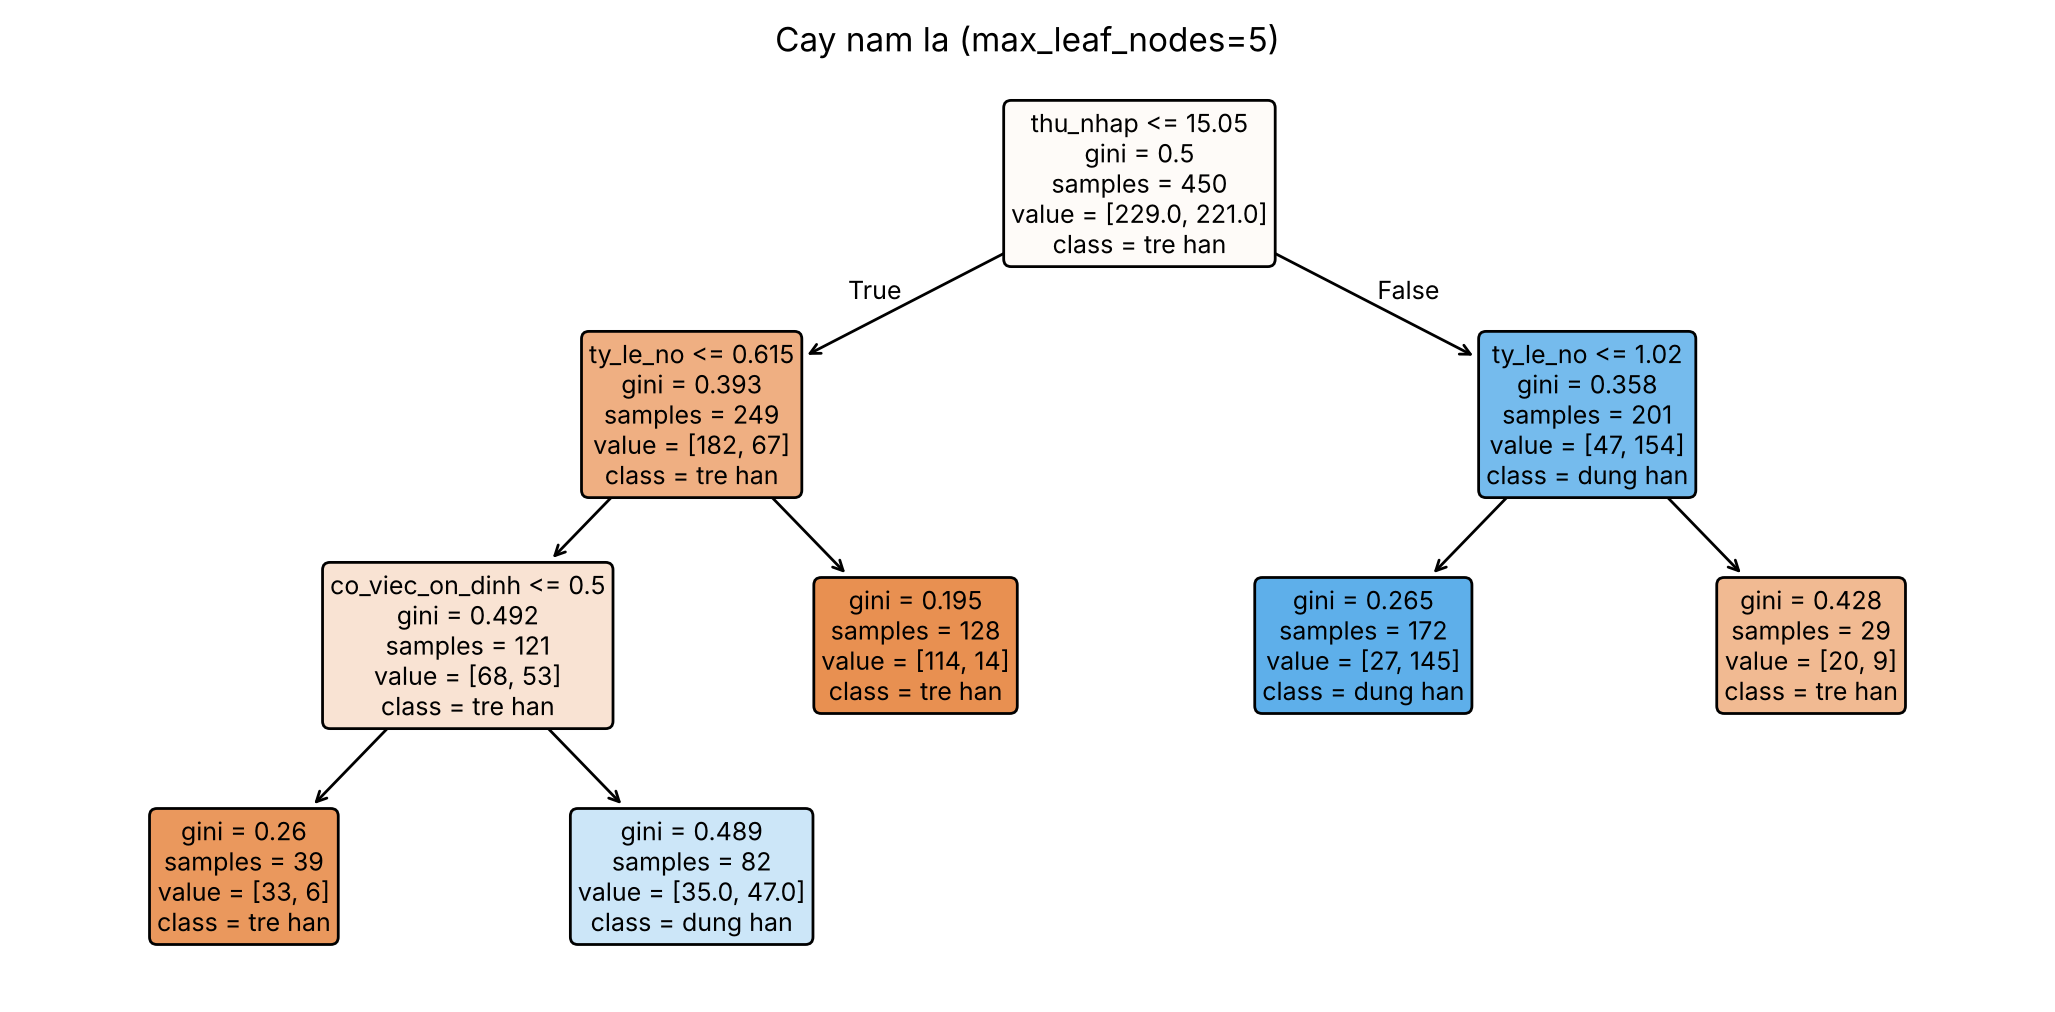

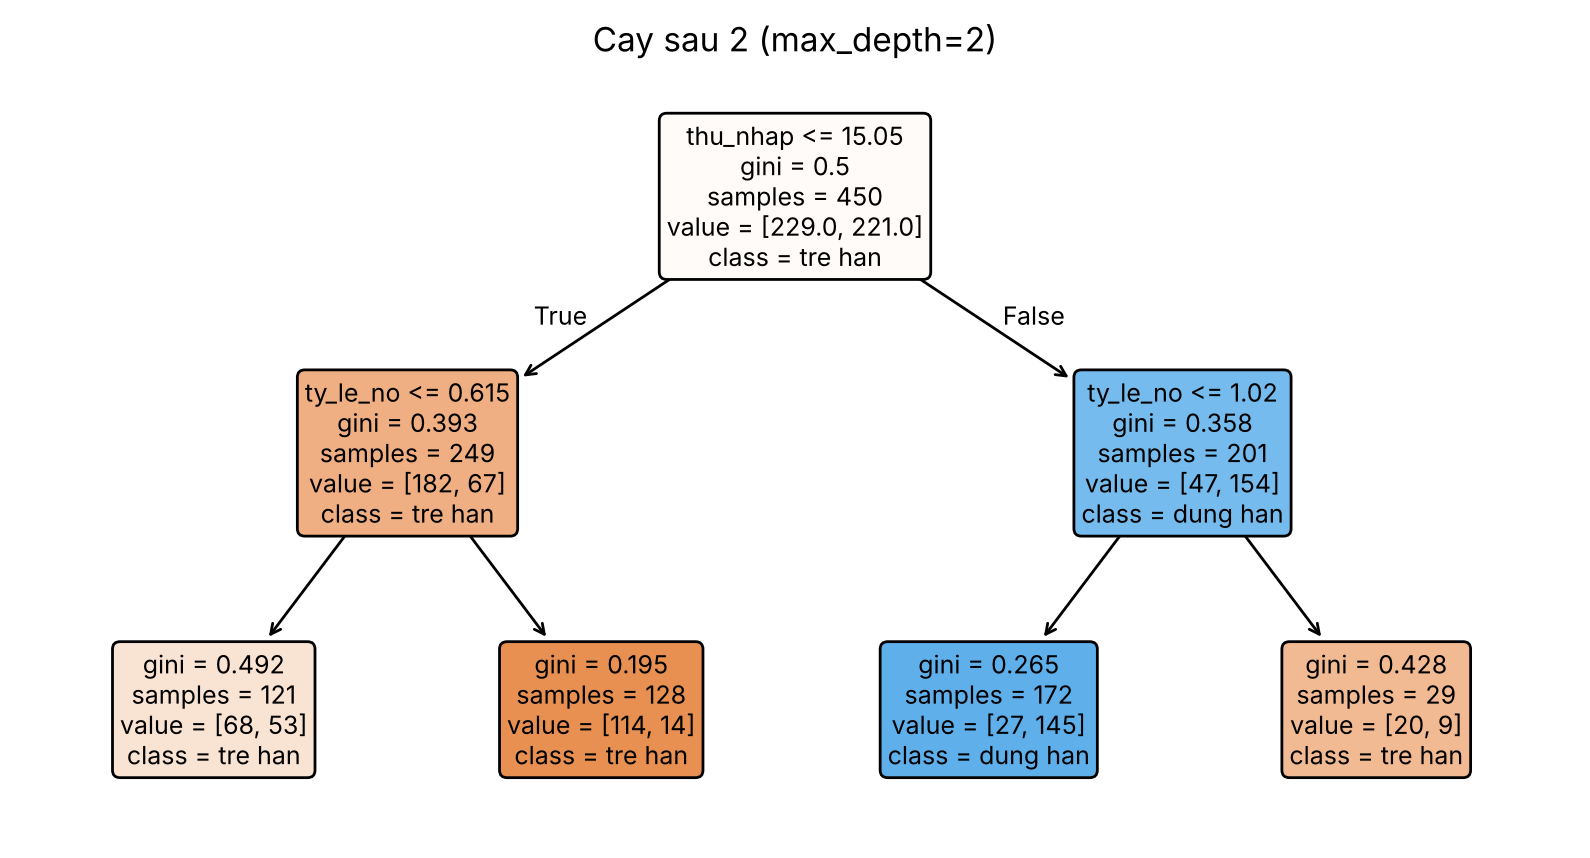

|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- weights: [68.000, 53.000] class: 0
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

La   so khach   khach tre   khach dung   ket luan   xac suat dung han
 2        121          68           53   tre han    0.438
 3        128         114           14   tre han    0.109
 5        172          27          145   dung han   0.843
 6         29          20            9   tre han    0.310


In [9]:
ten_cot = list(X.columns)
ten_lop = ["tre han", "dung han"]

# Cay nam la cua muc 3, ve bang plot_tree
plt.figure(figsize=(13, 6))
plot_tree(cay_nam_la, feature_names=ten_cot, class_names=ten_lop,
          filled=True, rounded=True, fontsize=9)
plt.title("Cay nam la (max_leaf_nodes=5)")
plt.savefig("cay_nam_la.png", dpi=150, bbox_inches="tight")
plt.show()

# Cay sau 2
cay_sau_2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_tr, y_tr)
plt.figure(figsize=(10, 5))
plot_tree(cay_sau_2, feature_names=ten_cot, class_names=ten_lop,
          filled=True, rounded=True, fontsize=9)
plt.title("Cay sau 2 (max_depth=2)")
plt.savefig("cay_sau_2.png", dpi=150, bbox_inches="tight")
plt.show()

# Kiem tra ket luan va xac suat o cac la cua cay sau 2
print(export_text(cay_sau_2, feature_names=ten_cot, show_weights=True, decimals=3))
la_cua_tung_khach = cay_sau_2.apply(X_tr)
print("La   so khach   khach tre   khach dung   ket luan   xac suat dung han")
for la in np.unique(la_cua_tung_khach):
    nhan_trong_la = y_tr[la_cua_tung_khach == la]
    ket_luan = ten_lop[int(nhan_trong_la.mean() > 0.5)]
    print(f"{la:2d}   {len(nhan_trong_la):8d}   {(nhan_trong_la == 0).sum():9d}   "
          f"{(nhan_trong_la == 1).sum():10d}   {ket_luan:8s}   {nhan_trong_la.mean():.3f}")

**Nhận xét:** Hai lá bên trái của cây sâu 2 (lá 121 khách và lá 128 khách) **cùng kết luận trễ hạn**. Cây vẫn chia vì tiêu chí chia là làm Gini giảm chứ không phải làm kết luận đổi. Nút cha (249 khách) có Gini 0.393, sau khi chia hai con có Gini 0.492 và 0.195, trung bình có trọng số khoảng 0.339, thấp hơn nên cây chia. Hai lá khác nhau rất rõ về độ chắc chắn: lá thứ nhất có xác suất đúng hạn 0.438 (gần chia đôi, 68 trễ và 53 đúng hạn), lá thứ hai chỉ 0.109 (114 trễ và 14 đúng hạn). Nghĩa là phép chia không làm đổi nhãn dự đoán nhưng làm `predict_proba` đáng tin hơn, và cây không biết trước rằng bước chia sau sẽ giúp ích như ở cây năm lá, nơi lá 121 khách được chia tiếp bằng việc làm ổn định.

### Bài tập 2: Tự tìm câu hỏi gốc trên dữ liệu thật

In [10]:
def tim_cau_hoi(X_du_lieu, y_nhan):
    """Thu moi cot va moi nguong, tra ve (cot, nguong, gini giam nhieu nhat)."""
    y_mang = np.asarray(y_nhan)
    n_khach = len(y_mang)

    def gini_nut(nhan):
        if len(nhan) == 0:
            return 0.0
        p1 = nhan.mean()
        return 1 - p1 ** 2 - (1 - p1) ** 2

    gini_goc = gini_nut(y_mang)
    tot_nhat = (None, None, -1.0)
    for ten_cot_xet in X_du_lieu.columns:
        gia_tri = X_du_lieu[ten_cot_xet].to_numpy()
        cac_muc = np.sort(np.unique(gia_tri))
        for a, b in zip(cac_muc[:-1], cac_muc[1:]):
            nguong = (a + b) / 2
            di_trai = gia_tri <= nguong
            gini_chia = (di_trai.sum() / n_khach * gini_nut(y_mang[di_trai])
                         + (~di_trai).sum() / n_khach * gini_nut(y_mang[~di_trai]))
            giam = gini_goc - gini_chia
            if giam > tot_nhat[2]:
                tot_nhat = (ten_cot_xet, nguong, giam)
    return tot_nhat


cot_tot, nguong_tot, gini_giam = tim_cau_hoi(X_tr, y_tr)
print(f"Cau hoi tot nhat cua ham tu viet: {cot_tot} <= {nguong_tot:.4f}")
print(f"Gini giam: {gini_giam:.4f}")

# Doi chieu voi cau hoi goc cua cay scikit-learn
cay_doi_chieu = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_tr, y_tr)
cot_sklearn = X.columns[cay_doi_chieu.tree_.feature[0]]
nguong_sklearn = cay_doi_chieu.tree_.threshold[0]
print(f"Cau hoi goc cua scikit-learn    : {cot_sklearn} <= {nguong_sklearn:.4f}")
print("Trung nhau:", cot_tot == cot_sklearn and abs(nguong_tot - nguong_sklearn) < 1e-6)

# Gini giam cua tung cot tot nhat, de thay vi sao thu nhap thang
print()
print("Gini giam tot nhat theo tung cot")
for ten_cot_xet in X.columns:
    _, ng, g = tim_cau_hoi(X_tr[[ten_cot_xet]], y_tr)
    print(f" {ten_cot_xet:20s} nguong {ng:6.2f}   Gini giam {g:.4f}")

Cau hoi tot nhat cua ham tu viet: thu_nhap <= 15.0500
Gini giam: 0.1221
Cau hoi goc cua scikit-learn    : thu_nhap <= 15.0500
Trung nhau: True

Gini giam tot nhat theo tung cot
 thu_nhap             nguong  15.05   Gini giam 0.1221
 ty_le_no             nguong   0.60   Gini giam 0.0586
 co_viec_on_dinh      nguong   0.50   Gini giam 0.0329
 so_nguoi_phu_thuoc   nguong   2.50   Gini giam 0.0235


**Nhận xét:** Hàm `tim_cau_hoi` làm đúng việc của `f1_gini.py` nhưng thử mọi cột và mọi ngưỡng (trung điểm giữa hai giá trị liền nhau, cột 0/1 chỉ có ngưỡng 0.5), rồi giữ câu hỏi làm Gini giảm nhiều nhất. Trên 450 khách của tập học, kết quả là `thu_nhap <= 15.05` với Gini giảm 0.1221 (từ khoảng 0.50 xuống khoảng 0.38), trùng với câu hỏi gốc của scikit-learn. Bảng cuối cho thấy vì sao thu nhập thắng: tốt nhất của tỷ lệ nợ chỉ giảm 0.0586, việc làm 0.0329, số người phụ thuộc 0.0235. Cây chọn tham lam: nó chỉ so Gini giảm ngay tại nút đó, không tính xem câu hỏi nào mở đường cho các câu hỏi tốt hơn ở tầng dưới.

### Bài tập 3: Gini hay entropy

In [11]:
cay_entropy_tu_do = DecisionTreeClassifier(criterion="entropy", random_state=0)
cay_entropy_tu_do.fit(X_tr, y_tr)
print("Cay entropy moc tu do:",
      f"do sau {cay_entropy_tu_do.get_depth()}, {cay_entropy_tu_do.get_n_leaves()} la,",
      f"tap hoc {accuracy_score(y_tr, cay_entropy_tu_do.predict(X_tr)):.4f},",
      f"tap kiem tra {accuracy_score(y_te, cay_entropy_tu_do.predict(X_te)):.4f}")
print()

print("Do sau   tap hoc   kiem dinh cheo (entropy)   kiem dinh cheo (gini)")
diem_entropy = {}
for do_sau in range(1, 16):
    mo_hinh = DecisionTreeClassifier(max_depth=do_sau, criterion="entropy",
                                     random_state=0)
    diem_entropy[do_sau] = cross_val_score(mo_hinh, X_tr, y_tr, cv=5).mean()
    hoc = accuracy_score(y_tr, mo_hinh.fit(X_tr, y_tr).predict(X_tr))
    print(f" {do_sau:2d}      {hoc:.4f}    {diem_entropy[do_sau]:.4f}"
          f"                     {diem_theo_do_sau[do_sau]:.4f}")
do_sau_tot_entropy = max(diem_entropy, key=diem_entropy.get)
print()

cay_entropy_tot = DecisionTreeClassifier(max_depth=do_sau_tot_entropy,
                                         criterion="entropy", random_state=0)
cay_entropy_tot.fit(X_tr, y_tr)
acc_entropy = accuracy_score(y_te, cay_entropy_tot.predict(X_te))
print(f"Entropy: do sau tot nhat = {do_sau_tot_entropy}, "
      f"{cay_entropy_tot.get_n_leaves()} la, accuracy kiem tra = {acc_entropy:.4f}")
print(f"Gini   : do sau tot nhat = {do_sau_tot}, "
      f"{cay_tot.get_n_leaves()} la, accuracy kiem tra = {acc_cay_tot:.4f}")

Cay entropy moc tu do: do sau 13, 88 la, tap hoc 1.0000, tap kiem tra 0.7667

Do sau   tap hoc   kiem dinh cheo (entropy)   kiem dinh cheo (gini)
  1      0.7467    0.7244                     0.7244
  2      0.7711    0.7133                     0.7378
  3      0.7733    0.7489                     0.7511
  4      0.8511    0.8111                     0.8089
  5      0.8956    0.8222                     0.8333
  6      0.9111    0.8222                     0.8156
  7      0.9378    0.8089                     0.8067


  8      0.9533    0.7933                     0.7733


  9      0.9778    0.7844                     0.7800


 10      0.9867    0.7978                     0.7822
 11      0.9933    0.7911                     0.7756
 12      0.9978    0.7822                     0.7778
 13      1.0000    0.7822                     0.7733
 14      1.0000    0.7822                     0.7733
 15      1.0000    0.7867                     0.7733

Entropy: do sau tot nhat = 5, 23 la, accuracy kiem tra = 0.8467
Gini   : do sau tot nhat = 5, 27 la, accuracy kiem tra = 0.8533


**Nhận xét:** Đổi thước đo gần như không làm kết quả khác đi. Cả hai đều chọn độ sâu tốt nhất bằng 5. Entropy cho điểm kiểm định chéo 0.8222 (Gini 0.8333), cây có 23 lá (Gini 27 lá), accuracy kiểm tra 0.8467 so với 0.8533, tức chênh đúng 1 khách trên 150 nên không đủ để kết luận thước đo nào hơn. Cây mọc tự do cũng như nhau về accuracy kiểm tra (0.7667), chỉ khác số lá (88 so với 92). Lý do là Gini và entropy là hai hàm cong có hình dạng gần giống nhau, cùng bằng 0 ở nút thuần và cực đại ở nút chia đôi, nên thường chọn cùng một câu hỏi.

### Bài tập 4: Cắt tỉa bằng số khách tối thiểu ở lá

In [12]:
print("min_samples_leaf   so la   tap hoc   kiem dinh cheo")
diem_theo_la_toi_thieu = {}
for la_toi_thieu in [1, 2, 5, 10, 20, 40]:
    mo_hinh = DecisionTreeClassifier(min_samples_leaf=la_toi_thieu, random_state=0)
    diem_theo_la_toi_thieu[la_toi_thieu] = cross_val_score(
        mo_hinh, X_tr, y_tr, cv=5).mean()
    mo_hinh.fit(X_tr, y_tr)
    hoc = accuracy_score(y_tr, mo_hinh.predict(X_tr))
    print(f" {la_toi_thieu:10d}      {mo_hinh.get_n_leaves():6d}   {hoc:.4f}    "
          f"{diem_theo_la_toi_thieu[la_toi_thieu]:.4f}")
la_toi_thieu_tot = max(diem_theo_la_toi_thieu, key=diem_theo_la_toi_thieu.get)
print()

cay_cat_la = DecisionTreeClassifier(min_samples_leaf=la_toi_thieu_tot, random_state=0)
cay_cat_la.fit(X_tr, y_tr)
acc_cat_la = accuracy_score(y_te, cay_cat_la.predict(X_te))
print(f"min_samples_leaf tot nhat = {la_toi_thieu_tot}, {cay_cat_la.get_n_leaves()} la")
print()
print("So sanh cach cat tia (chon bang kiem dinh cheo, cham mot lan tren tap kiem tra)")
print(f" max_depth = {do_sau_tot}           : kiem dinh cheo "
      f"{diem_theo_do_sau[do_sau_tot]:.4f}, tap kiem tra {acc_cay_tot:.4f}")
print(f" min_samples_leaf = {la_toi_thieu_tot:2d}   : kiem dinh cheo "
      f"{diem_theo_la_toi_thieu[la_toi_thieu_tot]:.4f}, tap kiem tra {acc_cat_la:.4f}")

min_samples_leaf   so la   tap hoc   kiem dinh cheo


          1          92   1.0000    0.7733


          2          72   0.9467    0.7822
          5          46   0.8956    0.8067
         10          30   0.8600    0.8089
         20          17   0.8422    0.8089
         40           8   0.7822    0.7133

min_samples_leaf tot nhat = 10, 30 la

So sanh cach cat tia (chon bang kiem dinh cheo, cham mot lan tren tap kiem tra)
 max_depth = 5           : kiem dinh cheo 0.8333, tap kiem tra 0.8533
 min_samples_leaf = 10   : kiem dinh cheo 0.8089, tap kiem tra 0.8467


**Nhận xét:** Khi tăng `min_samples_leaf`, số lá giảm (92, 72, 46, 30, 17, 8) và accuracy tập học giảm dần, còn điểm kiểm định chéo tăng tới khoảng 0.81 ở mức 5 đến 20 rồi rơi xuống 0.7133 ở mức 40 vì lá quá lớn khiến cây quá đơn giản. Giá trị 10 và 20 hòa nhau ở điểm kiểm định chéo (0.8089), hàm `max` lấy giá trị đầu tiên là 10. So với cây sâu 5 của mục 4, **cắt tỉa theo độ sâu nhỉnh hơn** trên bộ dữ liệu này: điểm kiểm định chéo 0.8333 so với 0.8089, và accuracy kiểm tra 0.8533 so với 0.8467. Tuy nhiên chênh lệch ở tập kiểm tra chỉ là 1 khách trên 150, nên chưa đủ để nói chắc cách nào tốt hơn. Điều chắc chắn là cả hai cách đều thắng cây mọc tự do (0.7667).

### Bài tập 5: Độ quan trọng bằng cách xáo trộn

                    xao_tron_trung_binh  do_lech_chuan  feature_importances_  hang_xao_tron  hang_feature_importances
thu_nhap                         0.2993         0.0237                0.4269              1                         1
ty_le_no                         0.1863         0.0343                0.2696              2                         2
co_viec_on_dinh                  0.1013         0.0151                0.0773              3                         4
so_nguoi_phu_thuoc               0.0650         0.0227                0.0764              4                         5
so_ngau_nhien                    0.0017         0.0081                0.1499              5                         3

Accuracy cua rung_nn tren tap kiem tra: 0.9067


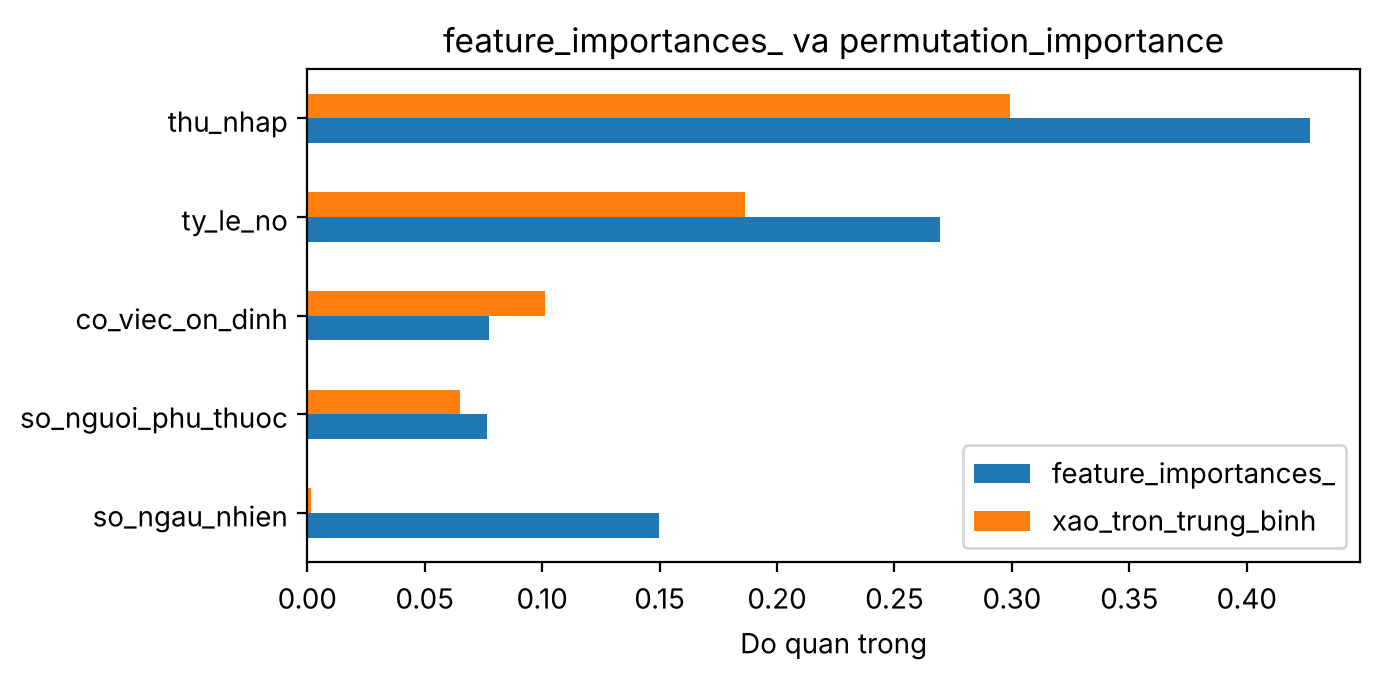

In [13]:
# Rung co cot so_ngau_nhien da hoc o muc 7 (rung_nn). Them cot tuong tu vao tap kiem tra
rng_kt = np.random.default_rng(1)
X_te_nn = X_te.copy()
X_te_nn["so_ngau_nhien"] = rng_kt.random(len(X_te))

ket_qua = permutation_importance(rung_nn, X_te_nn, y_te,
                                 n_repeats=20, random_state=0)
bang_xao_tron = pd.DataFrame({
    "xao_tron_trung_binh": ket_qua.importances_mean,
    "do_lech_chuan": ket_qua.importances_std,
    "feature_importances_": rung_nn.feature_importances_,
}, index=X_te_nn.columns)
bang_xao_tron["hang_xao_tron"] = bang_xao_tron["xao_tron_trung_binh"].rank(
    ascending=False).astype(int)
bang_xao_tron["hang_feature_importances"] = bang_xao_tron[
    "feature_importances_"].rank(ascending=False).astype(int)
print(bang_xao_tron.sort_values("xao_tron_trung_binh", ascending=False).round(4)
      .to_string())
print()
print("Accuracy cua rung_nn tren tap kiem tra:",
      round(accuracy_score(y_te, rung_nn.predict(X_te_nn)), 4))

bang_xao_tron[["feature_importances_", "xao_tron_trung_binh"]].sort_values(
    "xao_tron_trung_binh").plot.barh(figsize=(7, 3.5))
plt.xlabel("Do quan trong")
plt.title("feature_importances_ va permutation_importance")
plt.tight_layout()
plt.show()

**Nhận xét:** Theo `permutation_importance` (xáo trộn từng cột trên tập kiểm tra, lặp 20 lần), cột ngẫu nhiên xếp **thứ 5, cuối bảng**, với độ quan trọng trung bình chỉ 0.0017 và độ lệch chuẩn 0.0081, tức là không phân biệt được với 0. Theo `feature_importances_` cùng cột đó xếp **thứ 3** với 0.150, trên cả việc làm ổn định và số người phụ thuộc. Hai cách đo khác nhau vì: `feature_importances_` cộng lượng Gini giảm **trên tập học**, nơi cột nhiều giá trị luôn cho cây một ngưỡng nào đó ôm được vài khách, nên cây dùng cột này để học thuộc nhiễu và được cộng điểm. Cột này thực sự vô dụng với khách mới, và xáo trộn nó trên tập kiểm tra (nơi nó chỉ là nhiễu mới) không làm mô hình kém đi chút nào. Trái lại, xáo trộn thu nhập làm accuracy giảm trung bình 0.2993, tỷ lệ nợ 0.1863. Thứ hạng bốn cột thật theo cách xáo trộn là thu nhập, tỷ lệ nợ, việc làm ổn định, số người phụ thuộc, hợp lý hơn so với cách đầu. Hạn chế cần nhớ: kết quả dựa trên 150 khách kiểm tra và một cột ngẫu nhiên cụ thể, và cả hai cách đều chỉ đo mô hình dùng cột nào, không chứng minh quan hệ nhân quả.

### Bài tập 6: Rừng cho bài toán hồi quy

MAE tren tap kiem tra (ty dong)
 Rung 200 cay : 0.4559
 Cay sau 3    : 0.5039
 Duong thang  : 0.2578

Rung du doan can 250 m2 : 9.20 ty dong
Cay sau 3 du doan       : 9.40 ty dong
Duong thang du doan     : 19.91 ty dong

Gia thap nhat trong tap hoc : 3.87
Gia cao nhat trong tap hoc  : 9.74
Du doan thap nhat cua mot cay : 8.52
Du doan cao nhat cua mot cay  : 9.74
Trung binh 200 cay            : 9.20


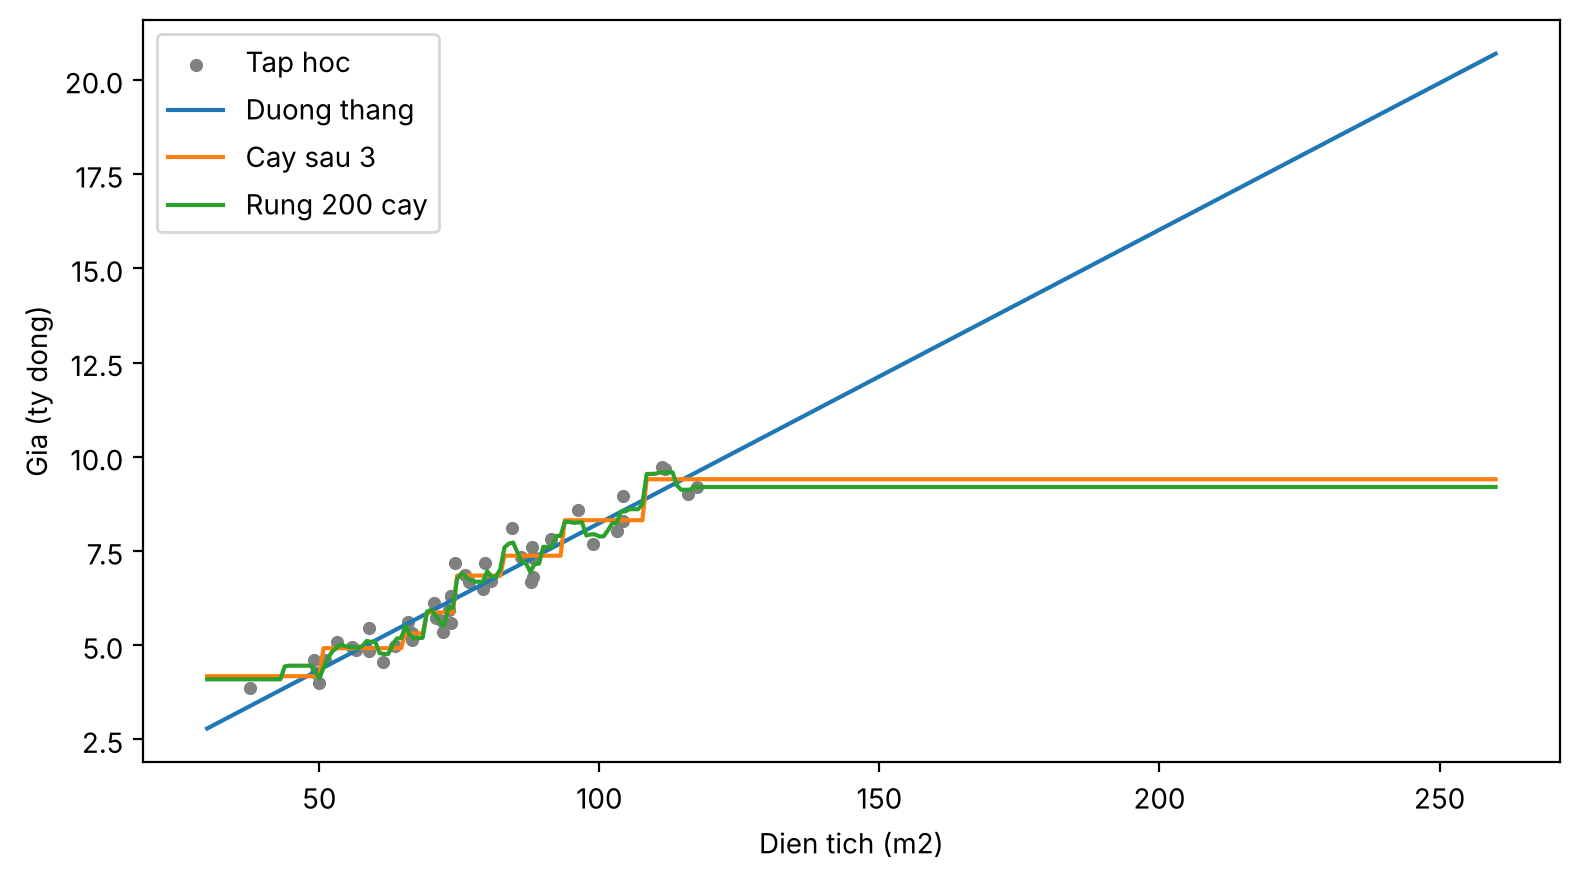

In [14]:
rung_hoi_quy = RandomForestRegressor(n_estimators=200, random_state=0)
rung_hoi_quy.fit(X_gia_tr, y_gia_tr)

mae_rung = mean_absolute_error(y_gia_te, rung_hoi_quy.predict(X_gia_te))
print("MAE tren tap kiem tra (ty dong)")
print(f" Rung 200 cay : {mae_rung:.4f}")
print(f" Cay sau 3    : {mae_cay:.4f}")
print(f" Duong thang  : {mae_duong:.4f}")
print()

can_250 = pd.DataFrame({"dien_tich": [250.0]})
print(f"Rung du doan can 250 m2 : {rung_hoi_quy.predict(can_250)[0]:.2f} ty dong")
print(f"Cay sau 3 du doan       : {cay_hoi_quy.predict(can_250)[0]:.2f} ty dong")
print(f"Duong thang du doan     : {duong_thang.predict(can_250)[0]:.2f} ty dong")
print()

# Mo tung cay trong rung de xem la nao dua ra du doan
du_doan_tung_cay = np.array([cay.predict(can_250.to_numpy())[0]
                             for cay in rung_hoi_quy.estimators_])
print(f"Gia thap nhat trong tap hoc : {y_gia_tr.min():.2f}")
print(f"Gia cao nhat trong tap hoc  : {y_gia_tr.max():.2f}")
print(f"Du doan thap nhat cua mot cay : {du_doan_tung_cay.min():.2f}")
print(f"Du doan cao nhat cua mot cay  : {du_doan_tung_cay.max():.2f}")
print(f"Trung binh 200 cay            : {du_doan_tung_cay.mean():.2f}")

# Ve ba duong du doan de thay vung ngoai suy
luoi = pd.DataFrame({"dien_tich": np.linspace(30, 260, 300)})
plt.figure(figsize=(8, 4.5))
plt.scatter(X_gia_tr, y_gia_tr, s=14, color="gray", label="Tap hoc")
plt.plot(luoi, duong_thang.predict(luoi), label="Duong thang")
plt.plot(luoi, cay_hoi_quy.predict(luoi), label="Cay sau 3")
plt.plot(luoi, rung_hoi_quy.predict(luoi), label="Rung 200 cay")
plt.xlabel("Dien tich (m2)")
plt.ylabel("Gia (ty dong)")
plt.legend()
plt.tight_layout()
plt.show()

**Nhận xét:** MAE trên tập kiểm tra là 0.4559 tỷ với rừng 200 cây, 0.5039 tỷ với cây sâu 3 và 0.2578 tỷ với đường thẳng. Rừng tốt hơn một cây đơn nhưng vẫn **thua đường thẳng**, vì giá nhà tăng gần như thẳng theo diện tích nên mô hình tuyến tính tận dụng được quan hệ đó, còn rừng chỉ đoán theo bậc thang. Căn 250 m² được rừng đoán 9.20 tỷ (cây đơn 9.40, đường thẳng 19.91). **Rừng không ngoại suy được.** Mỗi cây đoán bằng trung bình giá của các căn trong lá mà căn 250 m² rơi vào, tức là một trung bình của giá đã có trong tập học, nên không thể vượt khoảng giá đã thấy. Cụ thể giá trong tập học nằm từ 3.87 tới 9.74 tỷ, dự đoán của từng cây cho căn 250 m² nằm từ 8.52 tới 9.74, và trung bình 200 cây là 9.20, đều không vượt giá cao nhất đã thấy. Trong biểu đồ, đường của rừng đi ngang ở vùng diện tích lớn trong khi đường thẳng tiếp tục đi lên. Vì vậy khi dữ liệu mới nằm ngoài vùng đã học thì cả cây lẫn rừng đều chỉ lặp lại những gì đã thấy.